In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
from environment import AssetVecEnv

print('Numba JIT compile on first call — one-time delay...')

In [2]:
import sys
sys.path.insert(0, '/home/arthur/Documents/Workspace/Sandbox/GBRL/gbrl')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from stable_baselines3 import DQN
from stable_baselines3.common.callbacks import BaseCallback

from preprocessing import INDICATORS, preprocess
from finrl.meta.preprocessor.preprocessors import data_split
from environment import AssetVecEnv

# ── Data: first 18 months of ETH/USDT ────────────────────────────────────────

processed = preprocess()

START_18M = '2019-01-01 00:00:00'
END_18M   = '2020-07-01 00:00:00'
data_18m  = data_split(processed, START_18M, END_18M)

price_array = data_18m['close'].values.astype('float32')
tech_array  = data_18m[INDICATORS].values.astype('float32')
dates       = pd.to_datetime(data_18m['date'].values)

T, F = len(price_array), len(INDICATORS)
config = {'price_array': price_array, 'tech_array': tech_array, 'date': dates}

print(f"T={T} bars  |  F={F} features  |  ~{T/(24*30):.1f} months  ({START_18M[:10]} - {END_18M[:10]})")

# ── Hyper-params ──────────────────────────────────────────────────────────────

N_EPOCHS    = 32
N_ENVS_GRID = [1, 2, 4, 8, 16]
TRAIN_FREQ  = 32       # agent steps (env.step calls) between gradient updates
BATCH       = 256
LR          = 1e-4
GAMMA       = 0.99
INIT_CASH   = 1_000.0

# ── Equal grad steps proof ────────────────────────────────────────────────────
# learning_starts_N = T * N             (1 warmup epoch)
# total_timesteps_N = N_EPOCHS * T * N  (32 epochs x T steps x N envs)
# SB3 counts agent steps as TRAIN_FREQ per update; num_timesteps += n_envs/step
# grad_steps = (N_EPOCHS*T*N - T*N) / (TRAIN_FREQ * N)
#            = (N_EPOCHS - 1) * T / TRAIN_FREQ   <- constant in N  [EQUAL]

GRAD_STEPS = (N_EPOCHS - 1) * T // TRAIN_FREQ
print(f"\nGrad steps per config : {GRAD_STEPS:,}")
print(f"Target update every   : {T // TRAIN_FREQ} grad steps  (~1 per epoch)")


Data shape: (65989, 7)
Date range: 2017-12-31 23:00:00 -> 2025-07-17 13:00:00
Processed shape: (65989, 93)
Indicators (86): ['volume_adi', 'volume_obv', 'volume_cmf', 'volume_fi', 'volume_em', 'volume_sma_em', 'volume_vpt', 'volume_vwap', 'volume_mfi', 'volume_nvi', 'volatility_bbm', 'volatility_bbh', 'volatility_bbl', 'volatility_bbw', 'volatility_bbp', 'volatility_bbhi', 'volatility_bbli', 'volatility_kcc', 'volatility_kch', 'volatility_kcl', 'volatility_kcw', 'volatility_kcp', 'volatility_kchi', 'volatility_kcli', 'volatility_dcl', 'volatility_dch', 'volatility_dcm', 'volatility_dcw', 'volatility_dcp', 'volatility_atr', 'volatility_ui', 'trend_macd', 'trend_macd_signal', 'trend_macd_diff', 'trend_sma_fast', 'trend_sma_slow', 'trend_ema_fast', 'trend_ema_slow', 'trend_vortex_ind_pos', 'trend_vortex_ind_neg', 'trend_vortex_ind_diff', 'trend_trix', 'trend_mass_index', 'trend_dpo', 'trend_kst', 'trend_kst_sig', 'trend_kst_diff', 'trend_ichimoku_conv', 'trend_ichimoku_base', 'trend_ichim

TOTAL_TS=392,640  LS=3,272  GRAD_STEPS=12,167  EP_LEN=3272

n=1, full     n= 1  ep_len=None   gs= 1  grad=12,167
  epochs=30  elapsed=  73.7s  speed=5,326 ts/s  final=1193.5$

n=1, T/4      n= 1  ep_len=3272   gs= 1  grad=12,167
  epochs=30  elapsed=  74.1s  speed=5,299 ts/s  final=922.5$

n=2, T/4      n= 2  ep_len=3272   gs= 2  grad=12,166
  epochs=30  elapsed=  56.5s  speed=6,954 ts/s  final=1000.0$

n=4, T/4      n= 4  ep_len=3272   gs= 4  grad=12,164
  epochs=30  elapsed=  48.3s  speed=8,133 ts/s  final=915.6$

n=8, T/4      n= 8  ep_len=3272   gs= 8  grad=12,160
  epochs=30  elapsed=  44.2s  speed=8,889 ts/s  final=962.7$

n=16, T/4     n=16  ep_len=3272   gs=16  grad=12,160
  epochs=30  elapsed=  41.7s  speed=9,413 ts/s  final=1290.5$


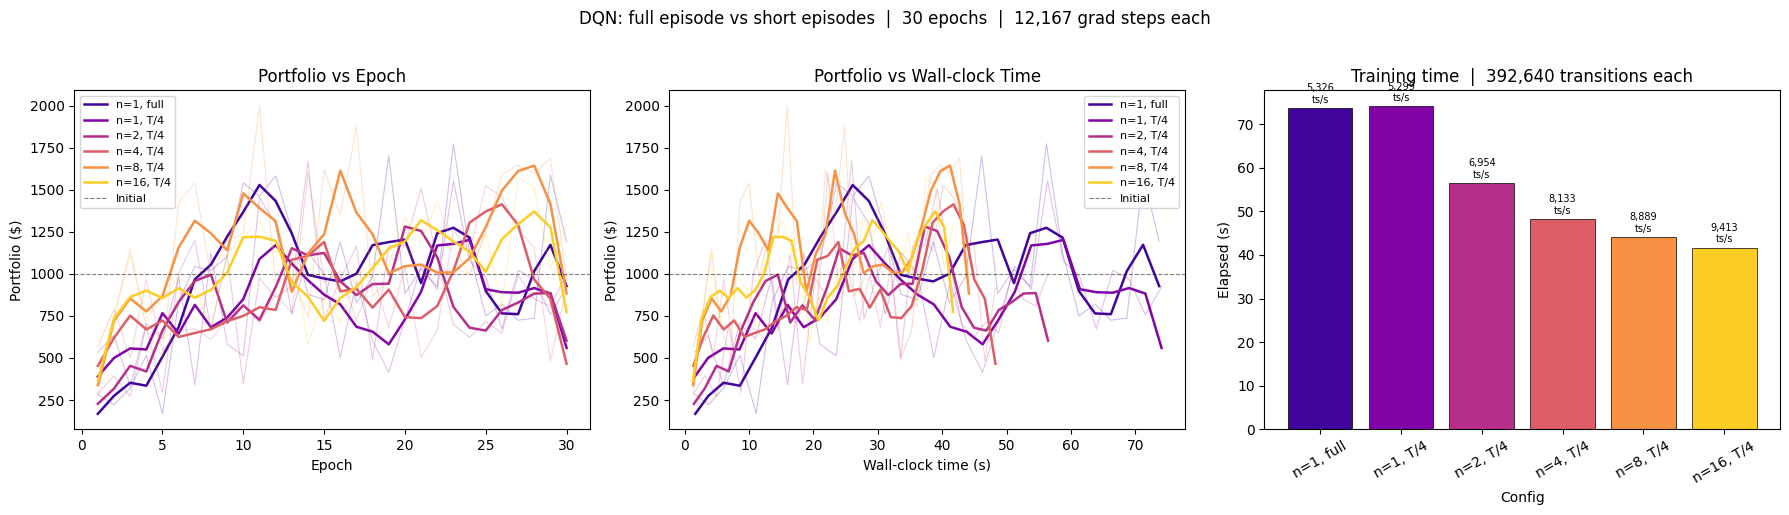


Config            Final $    Return   Time (s)      ts/s
---------------------------------------------------------
n=1, full          1193.5   +19.35%       73.7     5,326
n=1, T/4            922.5    -7.75%       74.1     5,299
n=2, T/4           1000.0    +0.00%       56.5     6,954
n=4, T/4            915.6    -8.44%       48.3     8,133
n=8, T/4            962.7    -3.73%       44.2     8,889
n=16, T/4          1290.5   +29.05%       41.7     9,413


In [6]:
import time

# ── Experiment 2: episode length effect ──────────────────────────────────────
# Compare baseline (n=1, full episode) vs n_envs × short episodes.
# All configs: same total transitions (30·T) and same total gradient steps.

N_EPOCHS_2 = 30
TOTAL_TS   = N_EPOCHS_2 * T       # SB3 timestep budget (= actual transitions)
LS_2       = T // 4               # warm-up: 1 short episode worth
EP_LEN     = T // 4               # short-episode window

# gradient_steps = n_envs  →  total grad = (TOTAL_TS-LS_2) / TRAIN_FREQ  (constant)
GRAD_STEPS_2 = (TOTAL_TS - LS_2) // TRAIN_FREQ
EPOCH_TS     = T   # T SB3 ts = T actual transitions per epoch, all configs

print(f'TOTAL_TS={TOTAL_TS:,}  LS={LS_2:,}  GRAD_STEPS={GRAD_STEPS_2:,}  EP_LEN={EP_LEN}')

# (label, n_envs, episode_len)
CONFIGS_2 = [
    ('n=1, full',  1,  None   ),
    ('n=1, T/4',   1,  EP_LEN ),
    ('n=2, T/4',   2,  EP_LEN ),
    ('n=4, T/4',   4,  EP_LEN ),
    ('n=8, T/4',   8,  EP_LEN ),
    ('n=16, T/4', 16,  EP_LEN ),
]


class EpochCallback2(BaseCallback):
    """Record portfolio value and elapsed time once per epoch (every T transitions)."""

    def __init__(self, eval_env, init_cash, epoch_ts, t0):
        super().__init__()
        self._eval_env   = eval_env
        self._init_cash  = init_cash
        self._epoch_ts   = epoch_ts
        self._t0         = t0
        self.epoch_vals  = []
        self.epoch_times = []
        self._next_eval  = epoch_ts

    def _on_step(self):
        while self.num_timesteps >= self._next_eval:
            self.epoch_vals.append(self._greedy_value())
            self.epoch_times.append(time.perf_counter() - self._t0)
            self._next_eval += self._epoch_ts
        return True

    def _greedy_value(self):
        obs  = self._eval_env.reset()
        done = np.zeros(1, dtype=bool)
        ret  = 0.0
        while not done[0]:
            action, _ = self.model.predict(obs, deterministic=True)
            obs, _, done, infos = self._eval_env.step(action)
            if done[0] and 'episode' in infos[0]:
                ret = infos[0]['episode']['r']
        return self._init_cash * (1.0 + ret)


# ── Sweep ─────────────────────────────────────────────────────────────────────

results2 = {}   # label -> {'vals', 'times', 'elapsed', 'n_envs', 'ep_len'}

for label, n_envs, ep_len in CONFIGS_2:
    gs  = n_envs                        # equal grad steps across configs
    tui = max(1, T // TRAIN_FREQ)       # target-net update ~once per epoch
    actual_grad = (TOTAL_TS - LS_2) // (TRAIN_FREQ * n_envs) * n_envs

    print(f'\n{label:12s}  n={n_envs:2d}  ep_len={str(ep_len):5s}  '
          f'gs={gs:2d}  grad={actual_grad:,}')

    train_env = AssetVecEnv(config, n_envs=n_envs, episode_len=ep_len,
                            initial_cash=INIT_CASH)
    eval_env  = AssetVecEnv(config, n_envs=1, episode_len=None,
                            initial_cash=INIT_CASH)

    model = DQN(
        'MlpPolicy', train_env,
        learning_rate          = LR,
        buffer_size            = min(TOTAL_TS, 500_000),
        learning_starts        = LS_2,
        batch_size             = BATCH,
        gamma                  = GAMMA,
        train_freq             = TRAIN_FREQ,
        gradient_steps         = gs,
        target_update_interval = tui,
        policy_kwargs          = dict(net_arch=[64, 64]),
        verbose                = 0,
    )

    t0 = time.perf_counter()
    cb = EpochCallback2(eval_env, INIT_CASH, EPOCH_TS, t0)
    model.learn(total_timesteps=TOTAL_TS, callback=cb)
    elapsed = time.perf_counter() - t0

    results2[label] = {
        'vals':    cb.epoch_vals,
        'times':   cb.epoch_times,
        'elapsed': elapsed,
        'n_envs':  n_envs,
        'ep_len':  ep_len,
    }
    speed = TOTAL_TS / elapsed
    final = cb.epoch_vals[-1] if cb.epoch_vals else float('nan')
    print(f'  epochs={len(cb.epoch_vals):2d}  '
          f'elapsed={elapsed:6.1f}s  speed={speed:,.0f} ts/s  final={final:.1f}$')


# ── Plot ───────────────────────────────────────────────────────────────────────

def smooth2(x, w=3):
    return np.convolve(x, np.ones(w) / w, mode='same')


labels2  = [c[0] for c in CONFIGS_2]
cmap2    = plt.cm.plasma(np.linspace(0.1, 0.9, len(labels2)))
epochs2  = np.arange(1, N_EPOCHS_2 + 1)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for label, col in zip(labels2, cmap2):
    r    = results2[label]
    vals = np.array(r['vals'])
    tms  = np.array(r['times'])
    ep   = epochs2[:len(vals)]

    axes[0].plot(ep,  vals,           color=col, alpha=0.25, lw=0.8)
    axes[0].plot(ep,  smooth2(vals),  color=col, lw=1.8, label=label)

    axes[1].plot(tms, vals,           color=col, alpha=0.25, lw=0.8)
    axes[1].plot(tms, smooth2(vals),  color=col, lw=1.8, label=label)

for ax in axes[:2]:
    ax.axhline(INIT_CASH, color='k', ls='--', lw=0.8, alpha=0.5, label='Initial')
    ax.set_ylabel('Portfolio ($)')
    ax.legend(fontsize=8)

axes[0].set_xlabel('Epoch')
axes[0].set_title('Portfolio vs Epoch')
axes[1].set_xlabel('Wall-clock time (s)')
axes[1].set_title('Portfolio vs Wall-clock Time')

# Speed bar chart
elapsed_vals = [results2[lbl]['elapsed'] for lbl in labels2]
bars = axes[2].bar(labels2, elapsed_vals, color=cmap2, edgecolor='k', linewidth=0.5)
for i, (lbl, s) in enumerate(zip(labels2, elapsed_vals)):
    axes[2].text(i, s + max(elapsed_vals) * 0.01,
                 f'{TOTAL_TS/s:,.0f}\nts/s', ha='center', va='bottom', fontsize=7)
axes[2].set_xlabel('Config')
axes[2].set_ylabel('Elapsed (s)')
axes[2].set_title(f'Training time  |  {TOTAL_TS:,} transitions each')
axes[2].tick_params(axis='x', rotation=30)

fig.suptitle(
    f'DQN: full episode vs short episodes  |  '
    f'{N_EPOCHS_2} epochs  |  {GRAD_STEPS_2:,} grad steps each',
    y=1.02, fontsize=12,
)
plt.tight_layout()
plt.show()


# ── Summary ────────────────────────────────────────────────────────────────────

print(f"\n{'Config':14s}  {'Final $':>9}  {'Return':>8}  {'Time (s)':>9}  {'ts/s':>8}")
print('-' * 57)
for label in labels2:
    r = results2[label]
    v = r['vals'][-1] if r['vals'] else float('nan')
    t = r['elapsed']
    print(f"{label:14s}  {v:>9.1f}  {(v/INIT_CASH-1)*100:>+7.2f}%  "
          f"{t:>9.1f}  {TOTAL_TS/t:>8,.0f}")
